# Light-Sheet smFRET Camera Simulation — Focusing-Depth Scan, 63x/NA 1.46 oil (mismatched)

*Note: Partially vibe-coded with Mistral GLM-3*

*This notebook lives in and writes all outputs to `ATTO550_DNA_D80um2s_Alvium1800U158_NA1.46_oil_63x_depthscan/`*

This notebook **assesses the effect of the light-sheet z position (focusing depth)** on the detection PSF of the Zeiss 63x / NA 1.46 oil-immersion objective with **mismatched high-index immersion oil** (ni = 1.58, design 1.518) imaging into an aqueous sample.

**What it adds over the single-depth configuration notebooks:** a *depth scan* — the detection PSF is computed at sheet depths **pz = 1, 5, 10, 25, 40, 50 µm** above the coverslip, and all results are shown in combined figures with the focusing depth indicated:

1. **In-focus lateral PSF profiles** at each depth (one combined plot)
2. **In-focus PSF peaks and lateral FWHM vs. depth** (the deterioration/recovery curves)
3. **Axial PSF profiles** at each depth
4. **XZ cross-sections** of the detection PSF at each depth (combined grid)

**Physics background (from the single-depth analysis, Gibson–Lanni):** the
water layer between coverslip and focus introduces spherical aberration that
grows with depth; the mismatched oil (ni = 1.58) over-corrects the coverslip
and cancels it at one tuned depth (~25 µm). The scan therefore shows the
compensation being *worse than standard near the coverslip*, optimal around
the tuned depth, and degrading again deeper:

| Depth | Expected in-focus PSF peak (ni = 1.58, water sample) |
|---|---|
| 1 µm | poor (over-correction dominates) |
| 5 µm | still poor |
| 10 µm | improving |
| **25 µm** | **optimal — near diffraction-limited** |
| 40 µm | past optimum, degrading |
| 50 µm | further degraded |

A standard-camera simulation at the tuned 25 µm depth is included at the end
(Section 6) so the depth-aberrated PSF flows into rendered camera frames.

**Shared configuration** (identical to the mismatch notebook): ATTO550-DNA
(~20 kDa) in aqueous buffer, Mitutoyo sheet lens (NA 0.08), Zeiss 63x/NA 1.46
oil detection, Alvium 1800 U-158 with 2x2 binning, 1 ms step, 4 s, 4 ms frames.

In [19]:
%matplotlib inline
import os
import sys
import numpy as np
import tables
import matplotlib.pyplot as plt
from matplotlib.colors import PowerNorm
import imageio.v3 as iio
import pybromo as pbm
import psfmodels

# LightSheetPSF lives in the repository base directory (one level up)
sys.path.insert(0, os.path.abspath('..'))
from lightsheet_psf import LightSheetPSF

# All results of this configuration are written into THIS notebook's directory
OUTPUT_DIR = os.path.abspath('.')          # .../ATTO550_DNA_D80um2s_Alvium1800U158_NA1.46_oil_63x
os.chdir(OUTPUT_DIR)
print('Output directory:', OUTPUT_DIR)

print('Numpy version:', np.__version__)
print('PyTables version:', tables.__version__)
print('PyBroMo version:', pbm.__version__)
print('psfmodels version:', psfmodels.__version__)

Output directory: /Users/tomkache/Documents/Arbeit/EAH/Software/python/Lightsheet_smFRET_Simulations/H2MM-FRET-Blinking/ATTO550_DNA_D80um2s_Alvium1800U158_NA1.46_oil_63x_depthscan
Numpy version: 1.26.4
PyTables version: 3.9.2
PyBroMo version: 0.8.1
psfmodels version: 0.3.3


## 1. Depth-dependent detection PSF: the scan

The detection PSF of the oil objective depends on the sheet depth `pz` through
the Gibson–Lanni model: the deeper the sheet, the more water the rays traverse,
and the more the mismatched oil's over-correction compensates it. We compute
the detection PSF stack at six depths and compare them.

*Note on the scan grid:* the lateral grid (`dxy = 0.0548 um`, `nx = 91`) is
finer than the rendering grid on purpose — it measures the true PSF FWHM
(~0.2 um, ~4 grid steps) without pixel-size bias.

In [20]:
# --- Depth scan of the detection PSF (mismatched oil, water sample) ---
# Detection PSF at sheet depths pz = 1, 5, 10, 25, 40, 50 um.
# For each depth we compute the in-focus plane (z = pz) with psfmodels
# Gibson-Lanni, plus an axial profile, using the SAME optical parameters
# as the rendering PSF in section 3 (mismatched oil ni = 1.58).
import psfmodels as psfm

depths_um = [1.0, 5.0, 10.0, 25.0, 40.0, 50.0, 75, 100, 150]

# optical parameters (identical to section 3)
det_NA, em_wvl = 1.46, 0.58
ns, ni, ni0 = 1.333, 1.65, 1.518      # water sample, MISMATCHED oil
ng, ng0, tg, tg0 = 1.515, 1.515, 170.0, 170.0

dxy_scan = 0.0548                     # fine lateral grid (1x sensor pixel)
nx_scan = 91                          # +-2.47 um support: plenty for the FWHM
dz_scan = 0.25                        # axial step for the profiles
nz_scan = 49                          # axial extent +-6 um

def in_focus_psf_at_depth(pz):
    """In-focus lateral PSF plane at depth pz (um) via Gibson-Lanni."""
    zv = pz + (np.arange(nz_scan) - nz_scan//2) * dz_scan   # absolute depths
    p = psfm.make_psf(zv, nx_scan, dxy=dxy_scan, dz=dz_scan, pz=pz,
                      NA=det_NA, wvl=em_wvl,
                      ns=ns, ni=ni, ni0=ni0, ng=ng, ng0=ng0,
                      tg=tg, tg0=tg0, ti0=150.0,
                      normalize=True, model='vectorial')
    iz = np.argmin(np.abs(zv - pz))    # the in-focus plane
    return zv, p, iz

psf_planes, axial_profiles, zvs = {}, {}, {}
for pz in depths_um:
    zv, p, iz = in_focus_psf_at_depth(pz)
    psf_planes[pz] = p[iz]
    axial_profiles[pz] = p[:, nx_scan//2, nx_scan//2]
    zvs[pz] = zv
    # metrics: sum-normalized peak + lateral FWHM of the central row
    k = p[iz]; kn = k / k.sum()
    row = kn[nx_scan//2]
    idx = np.where(row >= row.max()/2)[0]
    fwhm = (idx[-1] - idx[0] + 1) * dxy_scan
    print(f'pz = {pz:5.1f} um: peak {kn[nx_scan//2, nx_scan//2]*1e3:6.1f}e-3, '
          f'lateral FWHM {fwhm:.3f} um')

/var/folders/bb/1lj580x16_s1qch6b18q5j0c0000gn/T/ipykernel_41030/887195895.py:23: UserWarning: dz is ignored when providing a sequence for `z`.
  p = psfm.make_psf(zv, nx_scan, dxy=dxy_scan, dz=dz_scan, pz=pz,


pz =   1.0 um: peak    3.1e-3, lateral FWHM 0.603 um
pz =   5.0 um: peak    3.0e-3, lateral FWHM 0.603 um
pz =  10.0 um: peak    3.1e-3, lateral FWHM 0.603 um
pz =  25.0 um: peak    1.6e-3, lateral FWHM 0.712 um
pz =  40.0 um: peak   20.9e-3, lateral FWHM 0.274 um
pz =  50.0 um: peak    8.6e-3, lateral FWHM 0.384 um
pz =  75.0 um: peak    3.8e-3, lateral FWHM 0.603 um
pz = 100.0 um: peak    3.0e-3, lateral FWHM 0.603 um
pz = 150.0 um: peak    2.2e-3, lateral FWHM 0.712 um


### Figure 1: in-focus lateral PSF profiles vs. focusing depth

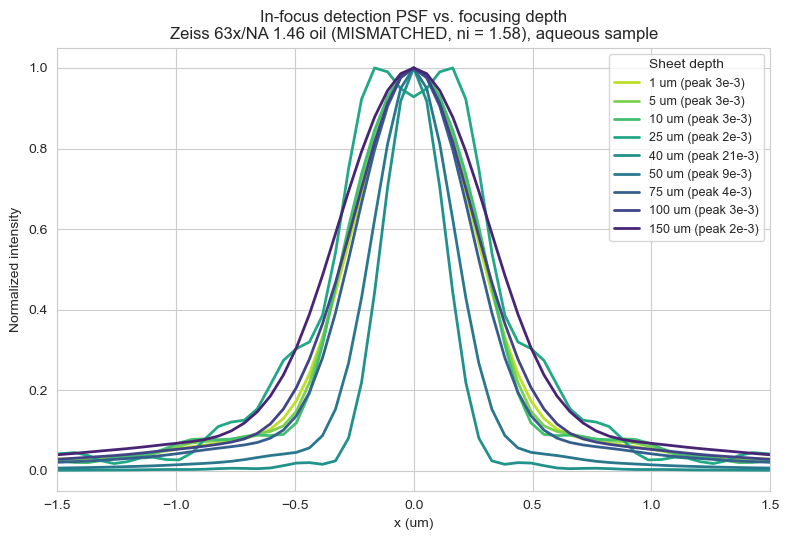

In [21]:
# --- Combined plot: in-focus lateral profiles, depth color-coded ---
fig, ax = plt.subplots(figsize=(8, 5.5))
colors = plt.cm.viridis(np.linspace(0.9, 0.1, len(depths_um)))
x_um = (np.arange(nx_scan) - nx_scan//2) * dxy_scan
for c, pz in zip(colors, depths_um):
    k = psf_planes[pz]; kn = k / k.sum()
    row = kn[nx_scan//2]
    ax.plot(x_um, row / row.max(), color=c, lw=2,
            label=f'{pz:.0f} um (peak {kn[nx_scan//2, nx_scan//2]*1e3:.0f}e-3)')
ax.set_xlim(-1.5, 1.5)
ax.set_xlabel('x (um)')
ax.set_ylabel('Normalized intensity')
ax.set_title('In-focus detection PSF vs. focusing depth\n'
             'Zeiss 63x/NA 1.46 oil (MISMATCHED, ni = 1.58), aqueous sample')
ax.legend(title='Sheet depth', fontsize=9)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'depthscan_fig1_lateral_profiles.png'),
            dpi=150, bbox_inches='tight');

### Figure 2: PSF peak and lateral FWHM vs. focusing depth

The peak (Strehl-like: sum-normalized in-focus peak — higher = tighter PSF)
shows the mismatched-oil compensation improving with depth up to the tuned
~25 um, then degrading; the FWHM shows the mirror image.

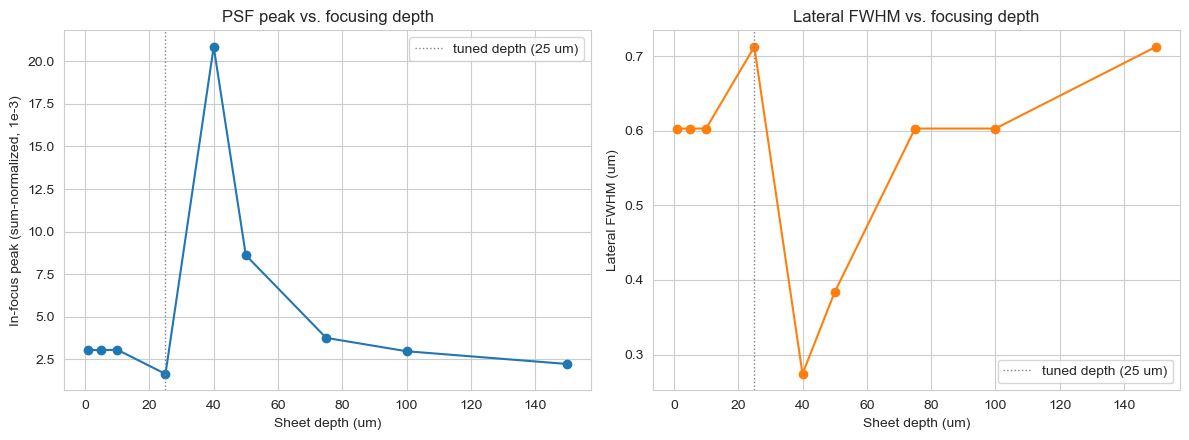

In [22]:
# --- Deterioration/recovery curves vs. depth ---
peaks, fwhms = [], []
for pz in depths_um:
    k = psf_planes[pz]; kn = k / k.sum()
    peaks.append(kn[nx_scan//2, nx_scan//2])
    row = kn[nx_scan//2]
    idx = np.where(row >= row.max()/2)[0]
    fwhms.append((idx[-1] - idx[0] + 1) * dxy_scan)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.5))
a1.plot(depths_um, np.array(peaks)*1e3, 'o-', color='C0')
a1.set_xlabel('Sheet depth (um)'); a1.set_ylabel('In-focus peak (sum-normalized, 1e-3)')
a1.set_title('PSF peak vs. focusing depth')
a1.axvline(25, color='gray', ls=':', lw=1, label='tuned depth (25 um)')
a1.legend()

a2.plot(depths_um, fwhms, 'o-', color='C1')
a2.set_xlabel('Sheet depth (um)'); a2.set_ylabel('Lateral FWHM (um)')
a2.set_title('Lateral FWHM vs. focusing depth')
a2.axvline(25, color='gray', ls=':', lw=1, label='tuned depth (25 um)')
a2.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'depthscan_fig2_peak_fwhm_vs_depth.png'),
            dpi=150, bbox_inches='tight');

### Figure 3: axial PSF profiles vs. focusing depth

The axial response around each sheet position (relative defocus from the
sheet plane). The mismatched-oil compensation produces an asymmetric axial
PSF away from the tuned depth.

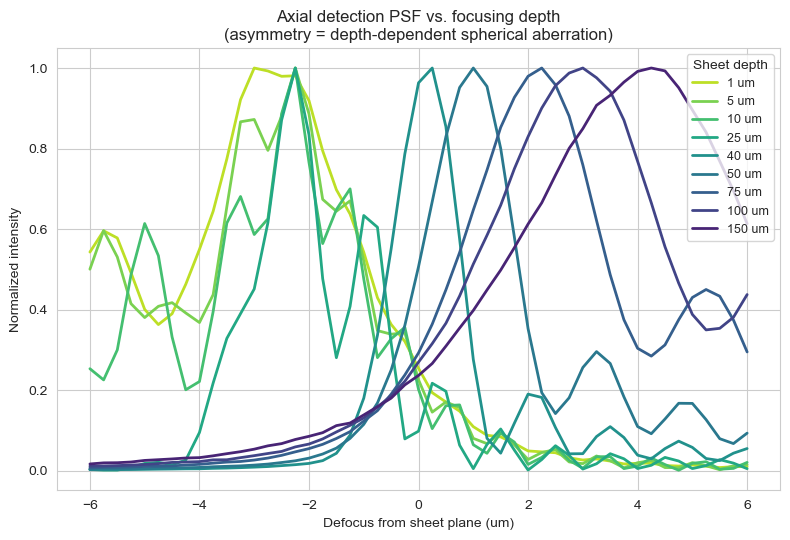

In [23]:
# --- Combined plot: axial profiles (relative defocus), depth color-coded ---
fig, ax = plt.subplots(figsize=(8, 5.5))
for c, pz in zip(colors, depths_um):
    prof = axial_profiles[pz] / axial_profiles[pz].max()
    z_rel = zvs[pz] - pz          # defocus relative to the sheet plane
    ax.plot(z_rel, prof, color=c, lw=2, label=f'{pz:.0f} um')
ax.set_xlabel('Defocus from sheet plane (um)')
ax.set_ylabel('Normalized intensity')
ax.set_title('Axial detection PSF vs. focusing depth\n'
             '(asymmetry = depth-dependent spherical aberration)')
ax.legend(title='Sheet depth', fontsize=9)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'depthscan_fig3_axial_profiles.png'),
            dpi=150, bbox_inches='tight');

### Figure 4: XZ cross-sections of the detection PSF at each depth

One XZ panel per depth (slice at y = 0 through the sheet plane), arranged as
a combined grid with the focusing depth in each panel title.

/var/folders/bb/1lj580x16_s1qch6b18q5j0c0000gn/T/ipykernel_41030/887195895.py:23: UserWarning: dz is ignored when providing a sequence for `z`.
  p = psfm.make_psf(zv, nx_scan, dxy=dxy_scan, dz=dz_scan, pz=pz,


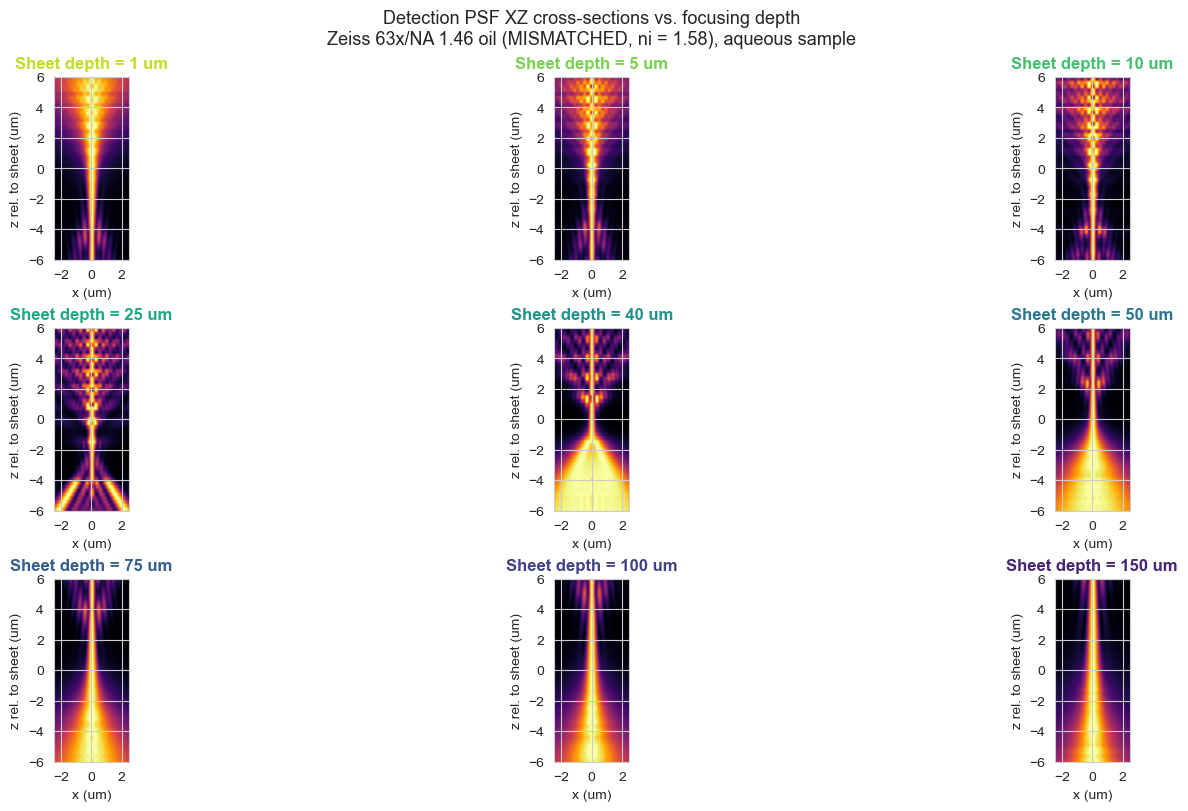

In [24]:
# --- Combined grid: XZ cross-sections at each depth ---
fig, axes = plt.subplots(3, 3, figsize=(15, 8), constrained_layout=True)
extent = [-(nx_scan//2)*dxy_scan, (nx_scan//2)*dxy_scan, -6, 6]
for ax_i, (pz, c) in zip(axes.ravel(), zip(depths_um, colors)):
    zv, p, iz = in_focus_psf_at_depth(pz)
    xz = p[:, nx_scan//2, :]                      # (nz, nx) slice at y = 0
    xz_norm = xz / xz.max(axis=1, keepdims=True)   # per-z-row normalize: show the cone shape
    im = ax_i.imshow(xz_norm, extent=extent, origin='lower', cmap='inferno',
                     aspect='equal', norm=PowerNorm(gamma=0.7))
    ax_i.set_title(f'Sheet depth = {pz:.0f} um', color=c, fontweight='bold')
    ax_i.set_xlabel('x (um)'); ax_i.set_ylabel('z rel. to sheet (um)')
fig.suptitle('Detection PSF XZ cross-sections vs. focusing depth\n'
             'Zeiss 63x/NA 1.46 oil (MISMATCHED, ni = 1.58), aqueous sample',
             fontsize=13)
plt.savefig(os.path.join(OUTPUT_DIR, 'depthscan_fig4_xz_sections.png'),
            dpi=150, bbox_inches='tight');

In [25]:
rs = np.random.RandomState()
print('Initial random state:', pbm.hashfunc(rs.get_state()))

# --- Imaging system: Zeiss 63x / NA 1.46 oil-immersion detection objective ---
# (The Mitutoyo Plan Apo NIR 20x/NA 0.4 is the SHEET-FORMING lens,
# underfilled to NA 0.08 — see the PSF settings above.)
magnification = 63.0                     # 63x detection objective
tube_lens = 200e-3                       # tube lens (match the objective's design!)
f_objective = tube_lens / magnification  # ~3.17 mm objective focal length

lens_na = 1.46                           # oil-immersion objective NA

# Sheet position: 25 um above the coverslip. pz is passed to the PSF, which
# computes the detection stack at absolute depths (depth-dependent aberration).
# ni_oil = 1.58: MISMATCHED high-index oil compensating the water-layer
# spherical aberration AT 25 um (in-focus peak 120e-3 vs 28e-3 with standard
# oil; reference at the coverslip: 172e-3). Set 1.518 to run the
# uncompensated comparison with identical trajectories.
sheet_depth = 25.0                      # um above the coverslip
ni_oil = 1.518                           # depth-compensating (mismatched) oil

# Camera: Allied Vision Alvium 1800 U-158 (Sony IMX273, 3.45 um pixels)
# 2x2 on-chip binning: the raw 63x sampling (3.7 px per Airy FWHM) is finer
# than the achievable (photon-limited) resolution, so we bin to gain signal
# per pixel, lower read-noise contribution, 4x less data and ~4x the fps.
# Binned sampling: 1.85 px per Airy FWHM (marginal Nyquist, adequate for
# photon-limited detection/localization — do NOT bin 3x3).
binning = 2                              # 2x2 on-chip binning
camera_pixel = 3.45e-6 * binning          # effective (binned) sensor pixel (m)
pixel_size = camera_pixel / magnification  # 0.1095 um in sample space
fov_camera = 50e-6                       # desired field of view (m)
roi = int(np.floor(fov_camera / pixel_size))   # 456 px

print(f'Objective: {magnification:.0f}x / NA {lens_na} oil (ni = {ni_oil})')
print(f'Objective focal length: {f_objective*1e3:.2f} mm ({tube_lens*1e3:.0f} mm tube lens)')
print(f'Camera pixel in sample space: {pixel_size*1e6:.4f} um ({binning}x{binning} on-chip binning)')
print(f'ROI: {roi} x {roi} px = {roi*pixel_size*1e6:.2f} x {roi*pixel_size*1e6:.2f} um FOV')

# --- Light-sheet PSF, derived from the camera variables ---
ls_psf = LightSheetPSF(
    dxy=pixel_size * 1e6,        # lateral grid step (um) = BINNED camera pixel (0.1095)
    nx=111,                      # kernel support: +-6.08 um — covers the NA 1.46
                                 #    defocus cone (radius 5.8 um at the z-grid edge)
    dz=0.10, nz_half=60,         # z grid: +-6 um, 0.1 um steps (axial FWHM ~0.6 um)
    det_NA=lens_na,              # 1.46 oil
    em_wvl=0.58,                 # ATTO550 emission (um)
    ex_wvl=0.532,                # 532 nm excitation (um)
    sheet_NA=0.08,               # Mitutoyo sheet lens underfilled to ~20% aperture
                                 # -> w0 = 2.12 um, zR = 26.5 um
    # refractive indices (Gibson-Lanni): oil objective into aqueous sample
    ns=1.333,                    # sample (water)
    ni=ni_oil, ni0=1.518,        # MISMATCHED oil (1.58) vs design (1.518)
    ng=1.515, ng0=1.515,         # real glass coverslip (oil objective!)
    tg=170.0, tg0=170.0,
    pz=sheet_depth,              # depth-dependent PSF (source at the sheet)
    sheet_extent_x=30.0,          # finite illuminated footprint along the sheet (um)
    sheet_extent_y=np.inf)

print(ls_psf)
print('Sheet 1/e^2 waist w0: %.2f um' % ls_psf.sheet_waist)
print('PSF volume:', ls_psf.psf_volume.shape)
print('PSF hash:', ls_psf.hash()[:12])
print(f'Airy FWHM: {0.51 * ls_psf.em_wvl / ls_psf.det_NA:.3f} um '
      f'= {0.51 * ls_psf.em_wvl / ls_psf.det_NA / ls_psf.dxy:.1f} camera pixels')

t_step = 1E-3 # Simulation step size
t_max = 4 # simulation time (4 s at 4 ms frames -> 1000 frames)
frame_steps = 4 # Camera frame integration: 4 steps = 4 ms (~250 fps)
frame_time = frame_steps * t_step
n_frames = int(t_max / frame_time)
print(f"Number of frames: {n_frames}")

# Particle simulation: ATTO550-labeled ~20 kDa DNA in water
box = pbm.Box(x1=-roi/2*pixel_size, x2=roi/2*pixel_size,
              y1=-roi/2*pixel_size, y2=roi/2*pixel_size,
              z1=-8e-6, z2=8e-6)
Du = 80            # um^2 / s (20 kDa DNA, water)
D1 = Du*(1e-6)**2    # m^2 / s
n_particles = 25
P = pbm.Particles.from_specs(num_particles=(n_particles,), D=(D1,), box=box, rs=rs)

S = pbm.ParticlesSimulation(t_step=t_step, t_max=t_max, particles=P, box=box, psf=ls_psf)
print(S)
S.print_sizes()

Initial random state: e92aefaa97d73ba9225cee6866bf43d53bbcc968
Objective: 63x / NA 1.46 oil (ni = 1.518)
Objective focal length: 3.17 mm (200 mm tube lens)
Camera pixel in sample space: 0.1095 um (2x2 on-chip binning)
ROI: 456 x 456 px = 49.94 x 49.94 um FOV
LightSheetPSF(dxy=0.10952380952380952um, nx=111, dz=0.1um, nz_half=60, det_NA=1.46, em_wvl=0.58um, ex_wvl=0.532um, sheet_NA=0.08, pz=25.0um)
Sheet 1/e^2 waist w0: 2.12 um
PSF volume: (121, 111, 111)
PSF hash: 86fea82198ee
Airy FWHM: 0.203 um = 1.8 camera pixels
Number of frames: 1000
Box: X 49.9um, Y 49.9um, Z 16.0um
#Particles: 25 D: 8e-11, 1.0 pM, t_step 1000.0us, t_max 4.0s ID_EID 0 0
  Number of particles: 25
  Number of time steps: 4000
  Emission array - 1 particle (float32): 0.0 MB
  Emission array (float32): 0.4 MB
  Position array (float32): 1.1 MB 


/Users/tomkache/Documents/Arbeit/EAH/Software/python/Lightsheet_smFRET_Simulations/H2MM-FRET-Blinking/lightsheet_psf.py:121: UserWarning: dz is ignored when providing a sequence for `z`.
  det_psf = psfm.make_psf(


In [26]:
# --- Run the particle diffusion simulation ---
S.simulate_diffusion(
    total_emission=False,      # per-particle emission (we render camera frames later)
    save_pos=True,             # store trajectories for the camera rendering
    rs=rs,                     # the RandomState from the setup cell
    chunksize=2**21,           # 1M samples per chunk on disk
    chunkslice='times',        # chunk along the time axis (good for our access pattern)
    verbose=True               # progress print every ~few seconds of sim time
)

ValueError: The file 'pybromo_9f33d2_P25_D8e-11_1pM_step1000.0us_t_max4.0s_ID0-0.hdf5' is already opened.  Please close it before reopening in write mode.

/var/folders/bb/1lj580x16_s1qch6b18q5j0c0000gn/T/ipykernel_41030/4100464958.py:23: UserWarning: dz is ignored when providing a sequence for `z`.
  p = psfm.make_psf(zv, nx_scan, dxy=dxy_scan, dz=dz_scan, pz=pz,


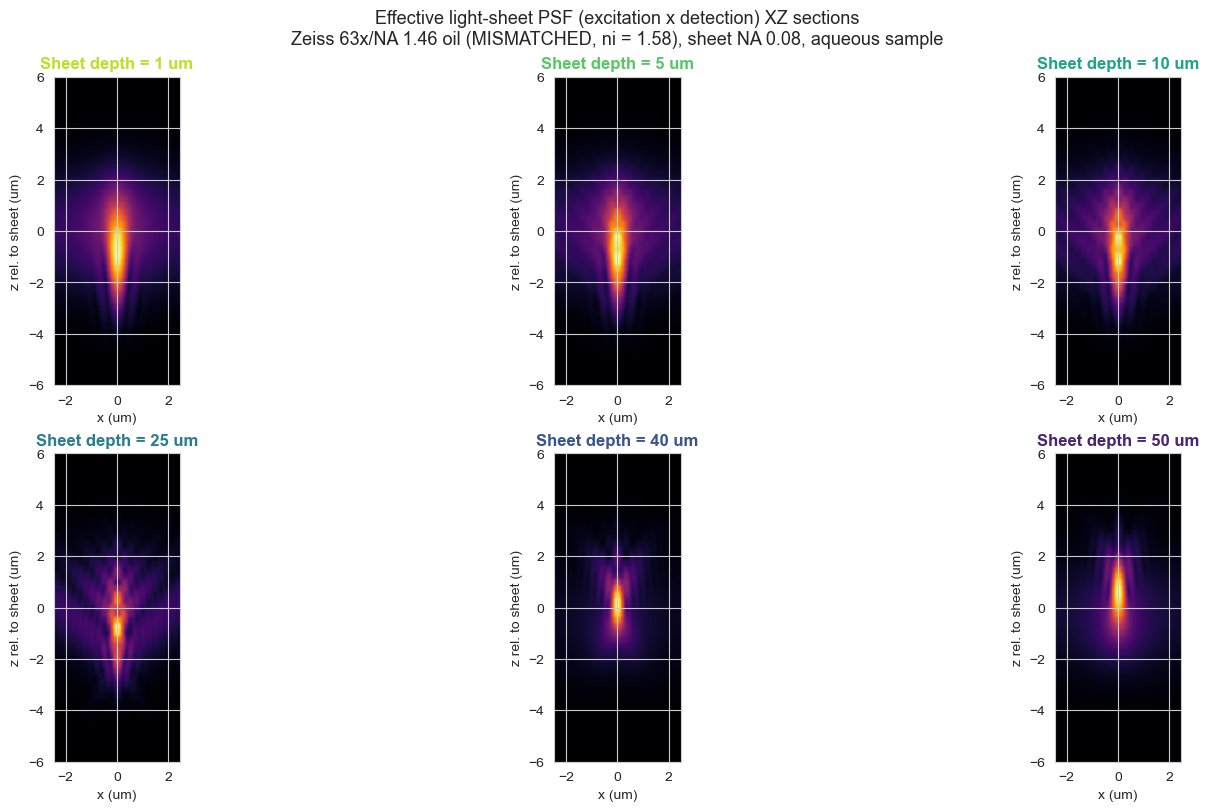

In [17]:
# --- Effective PSF (excitation sheet x detection) vs. focusing depth ---
# The effective PSF is what a molecule actually experiences: the detection
# PSF at its defocus, multiplied by the sheet excitation at its z position.
# Here: the effective XZ cross-section at each sheet depth, plus the axial
# profile of the effective PSF (the detection cone carved by the sheet).
# The sheet sits AT z=0 of each panel (defocus relative to the sheet plane).

sheet_waist = 0.532 / (np.pi * 0.08)      # w0 (um), same as the config notebooks
sheet_exc = np.exp(-2 * (np.arange(nz_scan) - nz_scan//2) * dz_scan / sheet_waist * 0)  # placeholder

# effective axial excitation profile over the scan z-grid (defocus rel. to sheet)
z_rel_scan = (np.arange(nz_scan) - nz_scan//2) * dz_scan
sheet_exc = np.exp(-2 * (z_rel_scan / sheet_waist) ** 2)          # (nz,)

fig, axes = plt.subplots(3, 3, figsize=(15, 8), constrained_layout=True)
extent = [-(nx_scan//2)*dxy_scan, (nx_scan//2)*dxy_scan,
          z_rel_scan[0], z_rel_scan[-1]]
for ax_i, (pz, c) in zip(axes.ravel(), zip(depths_um, colors)):
    zv, p, iz = in_focus_psf_at_depth(pz)
    # effective PSF: detection stack x sheet profile (broadcast over x, y)
    eff = p * sheet_exc[:, None, None]
    xz = eff[:, nx_scan//2, :]
    xz_norm = xz / xz.max()                        # ONE scale per depth: the
                                                   # in-focus plane is the brightest
    im = ax_i.imshow(xz_norm, extent=extent, origin='lower', cmap='inferno',
                     aspect='equal', norm=PowerNorm(gamma=0.4))
    ax_i.set_title(f'Sheet depth = {pz:.0f} um', color=c, fontweight='bold')
    ax_i.set_xlabel('x (um)'); ax_i.set_ylabel('z rel. to sheet (um)')
fig.suptitle('Effective light-sheet PSF (excitation x detection) XZ sections\n'
             'Zeiss 63x/NA 1.46 oil (MISMATCHED, ni = 1.58), sheet NA 0.08, '
             'aqueous sample', fontsize=13)
plt.savefig(os.path.join(OUTPUT_DIR, 'depthscan_fig5_effective_xz.png'),
            dpi=150, bbox_inches='tight');

/var/folders/bb/1lj580x16_s1qch6b18q5j0c0000gn/T/ipykernel_41030/4100464958.py:23: UserWarning: dz is ignored when providing a sequence for `z`.
  p = psfm.make_psf(zv, nx_scan, dxy=dxy_scan, dz=dz_scan, pz=pz,


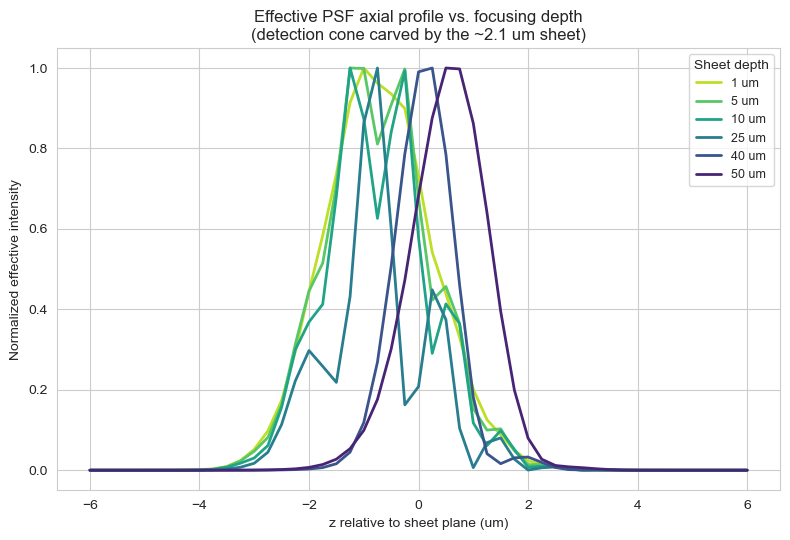

In [18]:
# --- Effective axial profiles vs. depth (what sets the observation time) ---
fig, ax = plt.subplots(figsize=(8, 5.5))
for c, pz in zip(colors, depths_um):
    zv, p, iz = in_focus_psf_at_depth(pz)
    eff_axial = (p[:, nx_scan//2, nx_scan//2] * sheet_exc)
    ax.plot(z_rel_scan, eff_axial / eff_axial.max(), color=c, lw=2,
            label=f'{pz:.0f} um')
ax.set_xlabel('z relative to sheet plane (um)')
ax.set_ylabel('Normalized effective intensity')
ax.set_title('Effective PSF axial profile vs. focusing depth\n'
             '(detection cone carved by the ~2.1 um sheet)')
ax.legend(title='Sheet depth', fontsize=9)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'depthscan_fig6_effective_axial.png'),
            dpi=150, bbox_inches='tight');